Text Summarization with Hugging Face

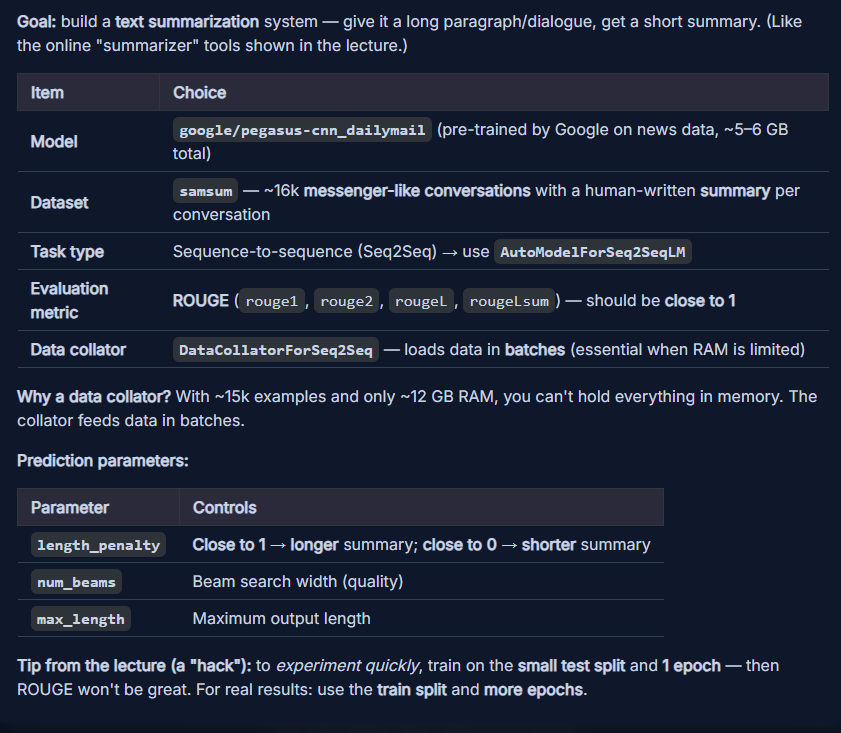

In [ ]:
!nvidia-smi
!pip install transformers datasets sentencepiece sacrebleu rouge_score py7zr accelerate

Tue Oct 20 09:32:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -U accelerate
!pip  uninstall -y transformers accelerate
!pip install transformers accelerate

Found existing installation: transformers 5.20.1
Uninstalling transformers-5.20.1:
  Successfully uninstalled transformers-5.20.1
Found existing installation: accelerate 1.15.0
Uninstalling accelerate-1.15.0:
  Successfully uninstalled accelerate-1.15.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 115.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 35.6 MB/s eta 0:00:00


In [ ]:
#imports & device check
import torch
from transformers import (pipeline, AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer)
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

Using: cuda


In [ ]:
#Load the tokenizer and the model
model_checkpoint = "google/pegasus-cnn_dailymail"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint).to(device)


config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/88.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/1.91M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.28GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.28GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/680 [00:00<?, ?it/s]

[transformers] PegasusForConditionalGeneration LOAD REPORT from: google/pegasus-cnn_dailymail
Key                                  | Status  | 
-------------------------------------+---------+-
model.encoder.embed_positions.weight | MISSING | 
model.decoder.embed_positions.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

In [ ]:
!pip install py7zr

In [ ]:
#load the dataset
dataset = load_dataset("knkarthick/samsum")
dataset            # columns: id, dialogue, summary
dataset["train"][0]["dialogue"]
dataset["train"][0]["summary"]

README.md:   0%|          | 0.00/4.36k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/9.26M [00:00<?, ?B/s]

validation.csv:   0%|          | 0.00/504k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/522k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/14731 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/818 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/819 [00:00<?, ? examples/s]

'Amanda baked cookies and will bring Jerry some tomorrow.'

In [ ]:
#Tokenize dialogue and summary
def convert_examples_to_features(example_batch):
    inputs = tokenizer(
        example_batch["dialogue"],
        max_length=1024,
        truncation=True,
    )
    targets = tokenizer(
        text_target=example_batch["summary"],
        max_length=128,
        truncation=True,
    )
    inputs["labels"] = targets["input_ids"]
    return inputs

dataset_pt = dataset.map(convert_examples_to_features, batched=True)
print(dataset_pt)

Map:   0%|          | 0/14731 [00:00<?, ? examples/s]

Map:   0%|          | 0/818 [00:00<?, ? examples/s]

Map:   0%|          | 0/819 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 14731
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 818
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 819
    })
})


In [ ]:
#Data collector(batch loading)
data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

In [ ]:
#training arguments

from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer

args = Seq2SeqTrainingArguments(
    output_dir="pegasus-samsum",
    num_train_epochs=1,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=8,
    eval_strategy="epoch",
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=10,
    save_strategy="no",
    report_to="none",
)

In [ ]:
#create the trainer
train_small = dataset_pt["train"].shuffle(seed=42).select(range(500))
val_small = dataset_pt["validation"].select(range(100))

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    processing_class=tokenizer,   # if you get an error here, use: tokenizer=tokenizer
    data_collator=data_collator,
    train_dataset=train_small,
    eval_dataset=val_small,
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,20.205656,2.220360


TrainOutput(global_step=32, training_loss=21.32644009590149, metrics={'train_runtime': 100.8501, 'train_samples_per_second': 4.958, 'train_steps_per_second': 0.317, 'total_flos': 271914403135488.0, 'train_loss': 21.32644009590149, 'epoch': 1.0})

In [15]:
#Evaluate with ROUGE
!pip install -q evaluate rouge_score

import numpy as np
import evaluate

rouge = evaluate.load("rouge")

# make predict() generate text instead of returning raw logits
trainer.args.predict_with_generate = True
trainer.args.generation_max_length = 128

test_small = dataset_pt["test"].select(range(10))
output = trainer.predict(test_small)

predictions = output.predictions
labels = output.label_ids

# replace -100 (ignored positions) so they can be decoded
predictions = np.where(predictions != -100, predictions, tokenizer.pad_token_id)
labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)
decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

print(rouge.compute(predictions=decoded_preds, references=decoded_labels))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.7 MB/s eta 0:00:00


{'rouge1': np.float64(0.3216643453549518), 'rouge2': np.float64(0.12053985540065597), 'rougeL': np.float64(0.2578085131415877), 'rougeLsum': np.float64(0.260989260714829)}


In [16]:
#saving the model and tokenizer
trainer.save_model("pegasus_samsum")
tokenizer.save_pretrained("pegasus_samsum")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('pegasus_samsum/tokenizer_config.json', 'pegasus_samsum/tokenizer.json')

In [20]:
sample = dataset["test"][0]["dialogue"]
reference = dataset["test"][0]["summary"]

inputs = tokenizer(sample, return_tensors="pt", truncation=True, max_length=1024).to(model.device)

ids = model.generate(
    **inputs,
    num_beams=8,
    length_penalty=0.8,
    max_length=128,
)

print("DIALOGUE :", sample)
print("\nREFERENCE:", reference)
print("\nPREDICTED:", tokenizer.decode(ids[0], skip_special_tokens=True))

DIALOGUE : Hannah: Hey, do you have Betty's number?
Amanda: Lemme check
Hannah: <file_gif>
Amanda: Sorry, can't find it.
Amanda: Ask Larry
Amanda: He called her last time we were at the park together
Hannah: I don't know him well
Hannah: <file_gif>
Amanda: Don't be shy, he's very nice
Hannah: If you say so..
Hannah: I'd rather you texted him
Amanda: Just text him 🙂
Hannah: Urgh.. Alright
Hannah: Bye
Amanda: Bye bye

REFERENCE: Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.

PREDICTED: Hannah asks Amanda for Betty's number .<n>Amanda can't find Betty's number .<n>Amanda asks Larry for Hannah's number .


In [22]:
!pip install -q evaluate rouge_score

In [23]:
import evaluate

rouge = evaluate.load("rouge")

test_samples = dataset["test"].select(range(10))
preds, refs = [], []

for ex in test_samples:
    inp = tokenizer(ex["dialogue"], return_tensors="pt", truncation=True, max_length=1024).to(model.device)
    out = model.generate(**inp, num_beams=4, length_penalty=0.8, max_length=128)
    preds.append(tokenizer.decode(out[0], skip_special_tokens=True))
    refs.append(ex["summary"])

print(rouge.compute(predictions=preds, references=refs))

{'rouge1': np.float64(0.34997773789000586), 'rouge2': np.float64(0.144122898155148), 'rougeL': np.float64(0.2923760494310549), 'rougeLsum': np.float64(0.29912579094864755)}


In [24]:
!pip install -q sentencepiece

model.save_pretrained("pegasus-samsum-final")
tokenizer.save_pretrained("pegasus-samsum-final")

!ls pegasus-samsum-final

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

config.json		model.safetensors      tokenizer.json
generation_config.json	tokenizer_config.json


In [21]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

my_tokenizer = AutoTokenizer.from_pretrained("pegasus-samsum-final")
my_model = AutoModelForSeq2SeqLM.from_pretrained("pegasus-samsum-final").to("cuda")

text = dataset["test"][1]["dialogue"]
inp = my_tokenizer(text, return_tensors="pt", truncation=True, max_length=1024).to("cuda")
out = my_model.generate(**inp, num_beams=8, length_penalty=0.8, max_length=128)

print("DIALOGUE :", text)
print("\nREFERENCE:", dataset["test"][1]["summary"])
print("\nPREDICTED:", my_tokenizer.decode(out[0], skip_special_tokens=True))

OSError: pegasus-samsum-final is not a local folder and is not a valid model identifier listed on 'https://huggingface.co/models'
If this is a private repository, make sure to pass a token having permission to this repo either by logging in with `hf auth login` or by passing `token=<your_token>`